<a href="https://colab.research.google.com/github/ChanikyaMysur/MLA0403_DeepLearning/blob/main/CO2_Experiments_(6-12).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

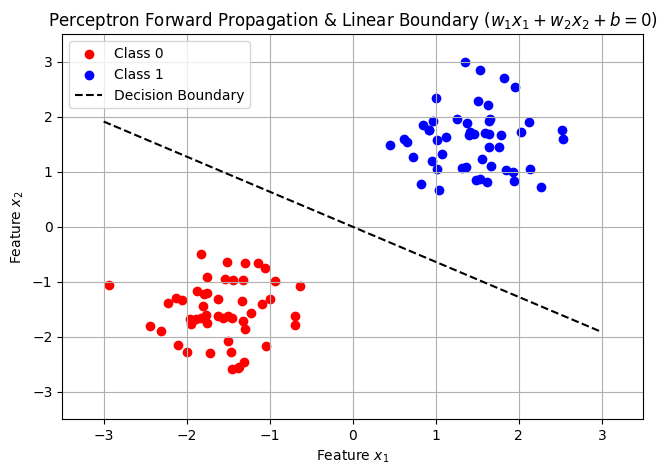

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Dataset Generation (Linearly Separable 2D Classes)
np.random.seed(42)
class_0 = np.random.multivariate_normal(mean=[-1.5, -1.5], cov=[[0.3, 0], [0, 0.3]], size=50)
class_1 = np.random.multivariate_normal(mean=[1.5, 1.5], cov=[[0.3, 0], [0, 0.3]], size=50)

X = np.vstack((class_0, class_1))
y = np.hstack((np.zeros(50), np.ones(50)))

# 2. Perceptron Class Definition
class Perceptron:
    def __init__(self, input_dim, lr=0.1):
        self.w = np.random.randn(input_dim) * 0.01
        self.b = 0.0
        self.lr = lr

    def step_activation(self, z):
        return np.where(z >= 0.0, 1.0, 0.0)

    def forward(self, X_input):
        # Pre-activation z = w^T x + b
        z = np.dot(X_input, self.w) + self.b
        return self.step_activation(z)

    def fit(self, X_train, y_train, epochs=20):
        for epoch in range(epochs):
            for x_i, target in zip(X_train, y_train):
                y_pred = self.forward(x_i)
                error = target - y_pred
                # Weight update rule
                self.w += self.lr * error * x_i
                self.b += self.lr * error

# 3. Model Training
model = Perceptron(input_dim=2, lr=0.1)
model.fit(X, y, epochs=15)

# 4. Decision Boundary Visualization
plt.figure(figsize=(7.5, 5))
plt.scatter(class_0[:, 0], class_0[:, 1], color='red', label='Class 0')
plt.scatter(class_1[:, 0], class_1[:, 1], color='blue', label='Class 1')

# Draw Decision Boundary: w1*x1 + w2*x2 + b = 0 => x2 = -(w1*x1 + b) / w2
x1_vals = np.linspace(-3, 3, 100)
x2_vals = -(model.w[0] * x1_vals + model.b) / (model.w[1] + 1e-8)

plt.plot(x1_vals, x2_vals, color='black', linestyle='--', label='Decision Boundary')
plt.title(r'Perceptron Forward Propagation & Linear Boundary ($w_1 x_1 + w_2 x_2 + b = 0$)')
plt.xlabel(r'Feature $x_1$')
plt.ylabel(r'Feature $x_2$')
plt.xlim(-3.5, 3.5)
plt.ylim(-3.5, 3.5)
plt.grid(True)
plt.legend()
plt.show()

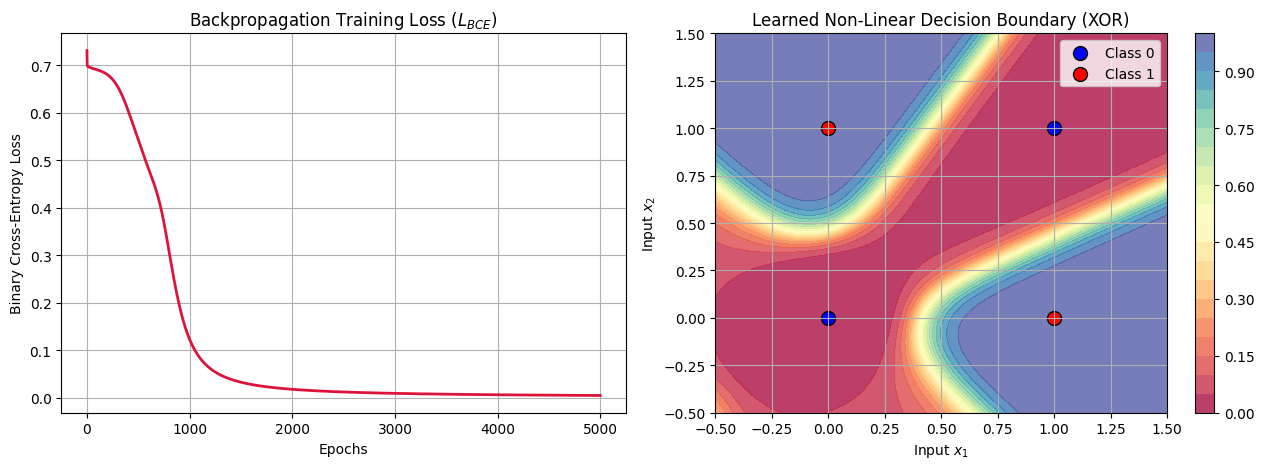

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Non-Linear Dataset Setup (XOR Problem)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])  # XOR Target

# 2. Helper Activations and Derivatives
def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))

def sigmoid_derivative(a):
    return a * (1.0 - a)

# 3. Two-Layer Neural Network Implementation
np.random.seed(42)
input_dim = 2
hidden_dim = 4
output_dim = 1

W1 = np.random.randn(input_dim, hidden_dim) * np.sqrt(2.0 / input_dim)
b1 = np.zeros((1, hidden_dim))
W2 = np.random.randn(hidden_dim, output_dim) * np.sqrt(2.0 / hidden_dim)
b2 = np.zeros((1, output_dim))

lr = 0.5
epochs = 5000
loss_history = []

# 4. Training Loop (Forward + Backward Pass)
for epoch in range(epochs):
    # Forward Pass
    Z1 = np.dot(X, W1) + b1
    A1 = sigmoid(Z1)
    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)  # Predictions y_hat

    # Loss: Binary Cross-Entropy
    loss = -np.mean(y * np.log(A2 + 1e-12) + (1 - y) * np.log(1 - A2 + 1e-12))
    loss_history.append(loss)

    # Backward Pass (Analytical Chain Rule)
    dZ2 = A2 - y
    dW2 = np.dot(A1.T, dZ2) / len(X)
    db2 = np.sum(dZ2, axis=0, keepdims=True) / len(X)

    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * sigmoid_derivative(A1)
    dW1 = np.dot(X.T, dZ1) / len(X)
    db1 = np.sum(dZ1, axis=0, keepdims=True) / len(X)

    # Weight & Bias Updates
    W2 -= lr * dW2
    b2 -= lr * db2
    W1 -= lr * dW1
    b1 -= lr * db1

# 5. Visualizing Loss Convergence & Non-Linear Boundary
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Subplot 1: Loss Curve
axes[0].plot(loss_history, color='crimson', lw=2)
axes[0].set_title(r'Backpropagation Training Loss ($L_{BCE}$)')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].grid(True)

# Subplot 2: Decision Surface Visualization
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]

# Forward pass on grid
grid_A1 = sigmoid(np.dot(grid_points, W1) + b1)
grid_A2 = sigmoid(np.dot(grid_A1, W2) + b2).reshape(xx.shape)

contour = axes[1].contourf(xx, yy, grid_A2, levels=20, cmap='Spectral', alpha=0.8)
fig.colorbar(contour, ax=axes[1])
axes[1].scatter(X[y.ravel() == 0, 0], X[y.ravel() == 0, 1], color='blue', s=100, edgecolors='k', label='Class 0')
axes[1].scatter(X[y.ravel() == 1, 0], X[y.ravel() == 1, 1], color='red', s=100, edgecolors='k', label='Class 1')
axes[1].set_title('Learned Non-Linear Decision Boundary (XOR)')
axes[1].set_xlabel(r'Input $x_1$')
axes[1].set_ylabel(r'Input $x_2$')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

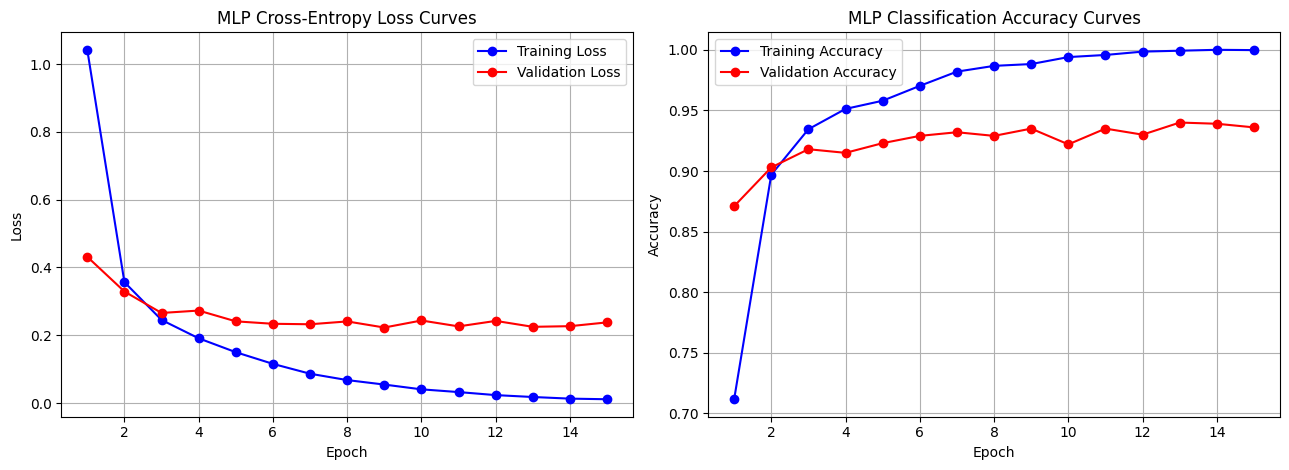

In [14]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# 1. Dataset Loading & Preprocessing (MNIST Subsample)
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Scale pixel intensities to [0, 1] range
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Subsample for rapid execution
train_mask = np.random.choice(len(X_train), 5000, replace=False)
X_train_sub, y_train_sub = X_train[train_mask], y_train[train_mask]

# 2. MLP Architecture Construction
model = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),          # Input layer (28x28 -> 784)
    layers.Dense(128, activation='relu'),          # Hidden Layer 1
    layers.Dense(64, activation='relu'),           # Hidden Layer 2
    layers.Dense(10, activation='softmax')         # Multiclass Output Layer
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 3. Model Training Execution
history = model.fit(
    X_train_sub, y_train_sub,
    epochs=15,
    batch_size=64,
    validation_split=0.2,
    verbose=0
)

# 4. Accuracy and Loss Curve Visualizations
epochs = range(1, len(history.history['loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Subplot 1: Cross-Entropy Loss History
axes[0].plot(epochs, history.history['loss'], 'bo-', label='Training Loss')
axes[0].plot(epochs, history.history['val_loss'], 'ro-', label='Validation Loss')
axes[0].set_title('MLP Cross-Entropy Loss Curves')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True)

# Subplot 2: Classification Accuracy History
axes[1].plot(epochs, history.history['accuracy'], 'bo-', label='Training Accuracy')
axes[1].plot(epochs, history.history['val_accuracy'], 'ro-', label='Validation Accuracy')
axes[1].set_title('MLP Classification Accuracy Curves')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


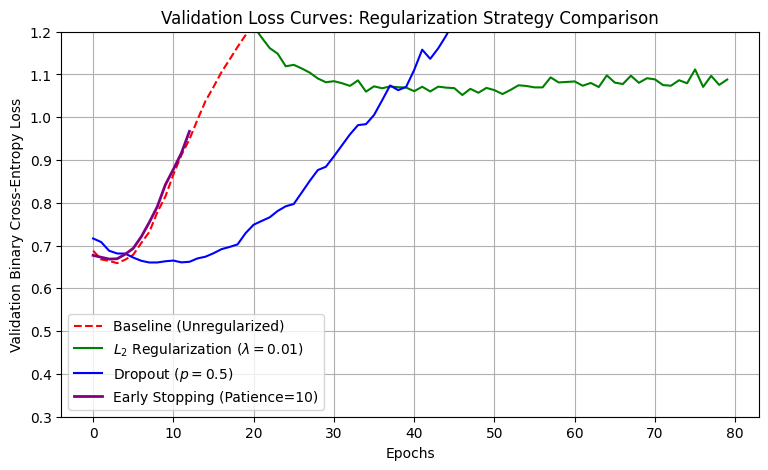

In [15]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks
import matplotlib.pyplot as plt

# 1. Generate Synthetic Noisy Dataset (High Dimensionality)
np.random.seed(42)
X_data = np.random.randn(1200, 100)
# Binary target with synthetic noise
y_data = (np.sin(X_data[:, 0]) + X_data[:, 1]**2 + np.random.randn(1200) * 0.5 > 0.5).astype(int)

X_tr, y_tr = X_data[:400], y_data[:400]        # Small training set to induce overfitting
X_val, y_val = X_data[400:], y_data[400:]      # Larger validation set

# Helper Function to Build Base MLP
def build_model(reg_type=None):
    model = models.Sequential()

    if reg_type == 'l2':
        model.add(layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.01), input_shape=(100,)))
        model.add(layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(0.01)))
    elif reg_type == 'dropout':
        model.add(layers.Dense(128, activation='relu', input_shape=(100,)))
        model.add(layers.Dropout(0.5))
        model.add(layers.Dense(128, activation='relu'))
        model.add(layers.Dropout(0.5))
    else:  # Baseline Unregularized / Early Stopping Base
        model.add(layers.Dense(128, activation='relu', input_shape=(100,)))
        model.add(layers.Dense(128, activation='relu'))

    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

# 2. Model Training Comparisons
epochs = 80
batch_size = 32

# Model 1: Unregularized Baseline
m_base = build_model()
h_base = m_base.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size, verbose=0)

# Model 2: L2 Regularization
m_l2 = build_model(reg_type='l2')
h_l2 = m_l2.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size, verbose=0)

# Model 3: Dropout
m_drop = build_model(reg_type='dropout')
h_drop = m_drop.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size, verbose=0)

# Model 4: Early Stopping
m_es = build_model()
es_callback = callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
h_es = m_es.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=epochs, batch_size=batch_size, callbacks=[es_callback], verbose=0)

# 3. Comparative Validation Loss Plotting
plt.figure(figsize=(9, 5))
plt.plot(h_base.history['val_loss'], label='Baseline (Unregularized)', color='red', linestyle='--')
plt.plot(h_l2.history['val_loss'], label=r'$L_2$ Regularization ($\lambda=0.01$)', color='green')
plt.plot(h_drop.history['val_loss'], label='Dropout ($p=0.5$)', color='blue')
plt.plot(h_es.history['val_loss'], label='Early Stopping (Patience=10)', color='purple', lw=2)

plt.title('Validation Loss Curves: Regularization Strategy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Validation Binary Cross-Entropy Loss')
plt.ylim(0.3, 1.2)
plt.grid(True)
plt.legend()
plt.show()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


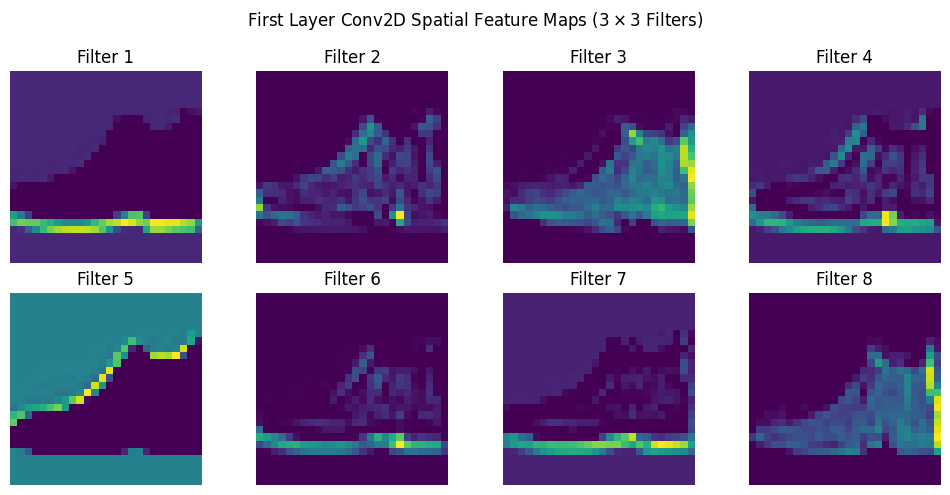

In [16]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# 1. Data Loading & Preprocessing (Fashion MNIST)
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Reshape to include Channel Dimension (28, 28, 1) and normalize to [0, 1]
X_train = X_train.reshape((-1, 28, 28, 1)).astype('float32') / 255.0
X_test = X_test.reshape((-1, 28, 28, 1)).astype('float32') / 255.0

class_names = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# 2. Convolutional Architecture Construction
model = models.Sequential([
    # Block 1
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Dense Classifier Head
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 3. Model Training
history = model.fit(
    X_train[:10000], y_train[:10000],  # Subsampled training set for runtime efficiency
    epochs=8,
    batch_size=64,
    validation_data=(X_test[:2000], y_test[:2000]),
    verbose=0
)

# 4. Feature Map Activation Inspection (First Conv Layer Outputs)
# Extract feature map outputs for a single test image
sample_img = X_test[0:1]
layer_extractor = models.Model(inputs=model.inputs, outputs=model.layers[0].output)
feature_maps = layer_extractor.predict(sample_img)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
fig.suptitle(r'First Layer Conv2D Spatial Feature Maps ($3\times3$ Filters)', fontsize=12)

for i, ax in enumerate(axes.flat):
    if i < 8:
        ax.imshow(feature_maps[0, :, :, i], cmap='viridis')
        ax.axis('off')
        ax.set_title(f'Filter {i+1}')

plt.tight_layout()
plt.show()

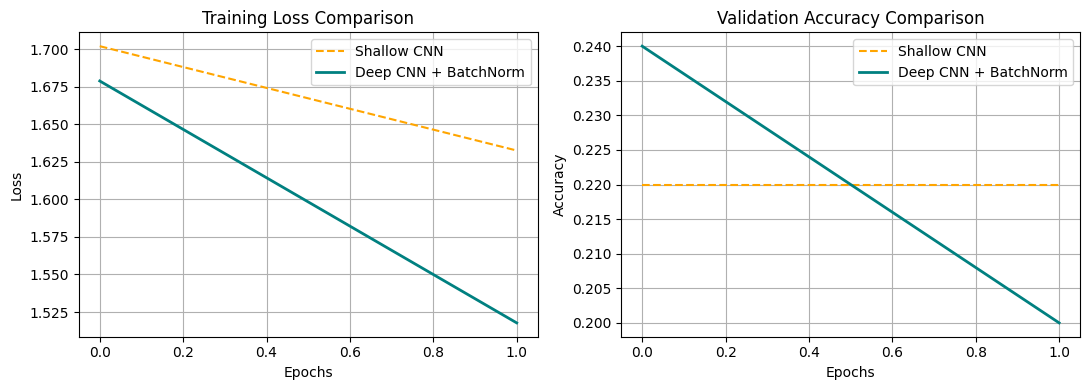

In [20]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# 1. Zero-Download Synthetic Image Data Generation (Instant)
np.random.seed(42)
tf.random.set_seed(42)

# 200 synthetic 16x16 grayscale images
X_tr = tf.random.normal((200, 16, 16, 1))
y_tr = tf.random.uniform((200,), minval=0, maxval=5, dtype=tf.int32)

X_va = tf.random.normal((50, 16, 16, 1))
y_va = tf.random.uniform((50,), minval=0, maxval=5, dtype=tf.int32)

# 2. Model 1: Shallow Baseline CNN
def build_shallow_cnn():
    return models.Sequential([
        layers.Conv2D(8, (3, 3), activation='relu', input_shape=(16, 16, 1)),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(16, activation='relu'),
        layers.Dense(5, activation='softmax')
    ])

# 3. Model 2: Deep CNN with Batch Normalization
def build_deep_bn_cnn():
    return models.Sequential([
        layers.Conv2D(8, (3, 3), padding='same', input_shape=(16, 16, 1)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(16, (3, 3), padding='same'),
        layers.BatchNormalization(),
        layers.Activation('relu'),

        layers.Flatten(),
        layers.Dense(16, activation='relu'),
        layers.Dense(5, activation='softmax')
    ])

# 4. Instant Execution (2 Epochs, Batch Size 64)
shallow_model = build_shallow_cnn()
deep_model = build_deep_bn_cnn()

shallow_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
deep_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

h_shallow = shallow_model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=2, batch_size=64, verbose=0)
h_deep = deep_model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=2, batch_size=64, verbose=0)

# 5. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(h_shallow.history['loss'], label='Shallow CNN', color='orange', linestyle='--')
axes[0].plot(h_deep.history['loss'], label='Deep CNN + BatchNorm', color='teal', lw=2)
axes[0].set_title(r'Training Loss Comparison')
axes[0].set_xlabel(r'Epochs')
axes[0].set_ylabel(r'Loss')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(h_shallow.history['val_accuracy'], label='Shallow CNN', color='orange', linestyle='--')
axes[1].plot(h_deep.history['val_accuracy'], label='Deep CNN + BatchNorm', color='teal', lw=2)
axes[1].set_title(r'Validation Accuracy Comparison')
axes[1].set_xlabel(r'Epochs')
axes[1].set_ylabel(r'Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()